# Notebook 1: PCM-FM waveform explanation

Steps 1 and 2 only: an offline explanation and executable integer contract. No radio access, HDL implementation, or Vivado build occurs here.

**Signal path:** PN15 → NRZ levels → sample hold → shaping FIR → frequency deviation → phase accumulator → sine/cosine → signed I/Q.

BPSK changed the sign of I directly. Here a bit changes the *rate of phase rotation*. The accumulated phase remains continuous even when the bit changes. The Pluto RF LO later translates these complex baseband samples to RF.

We reuse 2.5 MS/s and 8 samples/bit: 312.5 kbit/s. Nominal deviation is ±109.375 kHz, giving h = 2 Δf / Rb = 0.7. PCM framing is not implemented: PN15 provides the binary test stimulus.

[RCC 106-17, Appendix A.11](https://www.trmc.osd.mil/wiki/download/attachments/113019664/106-17_Telemetry_Standards.pdf?api=v2&modificationDate=1623181155137&version=1) discusses NRZ filtering and these nominal deviation parameters. This is a prototype, not a compliance-certified waveform.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pcm_fm import *
nrz, shaped, phase, ideal = reference(pn15(32767))
print(f'Fs={FS} Hz; Rb={RB} bit/s; deviation={DEVIATION} Hz')


Fs=2500000 Hz; Rb=312500.0 bit/s; deviation=109375.0 Hz


## 1. Bits become a smooth frequency command

Bit 0 maps to −1; bit 1 maps to +1. Each level is held for eight accepted samples. A causal 65-tap Hamming-windowed sinc FIR smooths transitions, with 32 samples (four bits) of group delay. Startup history is zero.

The chosen ideal sinc cutoff is 0.7 Rb = 218.75 kHz, approximately the −6 dB point of this FIR. It is **not** a specified −3 dB telemetry filter bandwidth. Its overshoot is preserved rather than clipped; nominal deviation refers to steady constant bits. Filter compliance and spectral-mask selection remain future work.

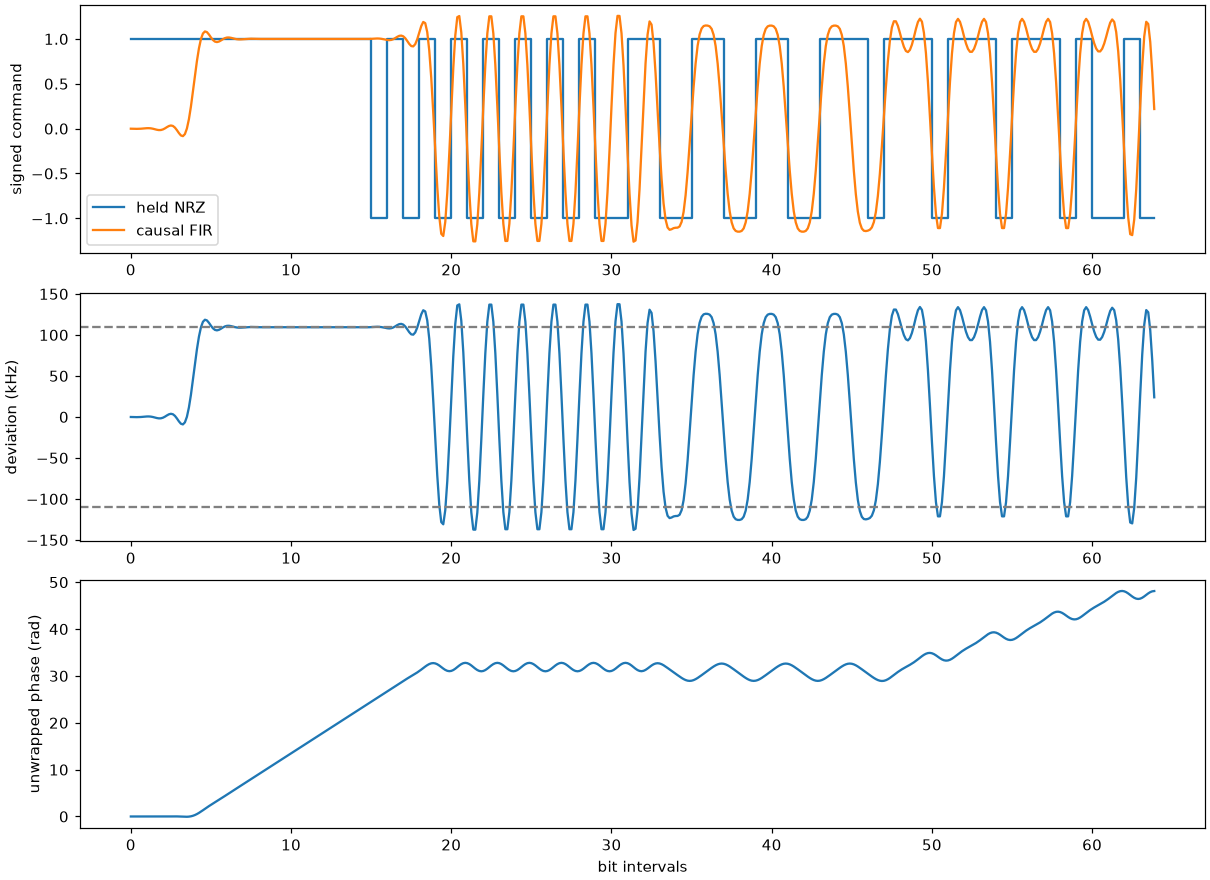

In [2]:
fig, ax = plt.subplots(3,1,figsize=(11,8),constrained_layout=True)
t = np.arange(512)/SPS
ax[0].step(t,nrz[:512],where='post',label='held NRZ'); ax[0].plot(t,shaped[:512],label='causal FIR'); ax[0].legend()
ax[0].set_ylabel('signed command')
ax[1].plot(t,shaped[:512]*DEVIATION/1000); ax[1].axhline(DEVIATION/1000,color='gray',ls='--'); ax[1].axhline(-DEVIATION/1000,color='gray',ls='--'); ax[1].set_ylabel('deviation (kHz)')
ax[2].plot(t,phase[:512]); ax[2].set_ylabel('unwrapped phase (rad)'); ax[2].set_xlabel('bit intervals')
fig.savefig('results/stages.png',dpi=150)
plt.show()

## 2. Frequency integrates into phase, then I/Q

For sample n, f[n] = Δf × shaped[n]. The phase update is φ[n] = φ[n−1] + 2π f[n]/Fs, starting with φ[−1] = 0. Output uses the updated phase: I[n] = A cos(φ[n]), Q[n] = A sin(φ[n]), with A = 16384.

The ideal envelope is constant. Wrapping numerical phase modulo 2π does not create a waveform discontinuity. The positive sign convention makes a positive command rotate counterclockwise in the I/Q plane.

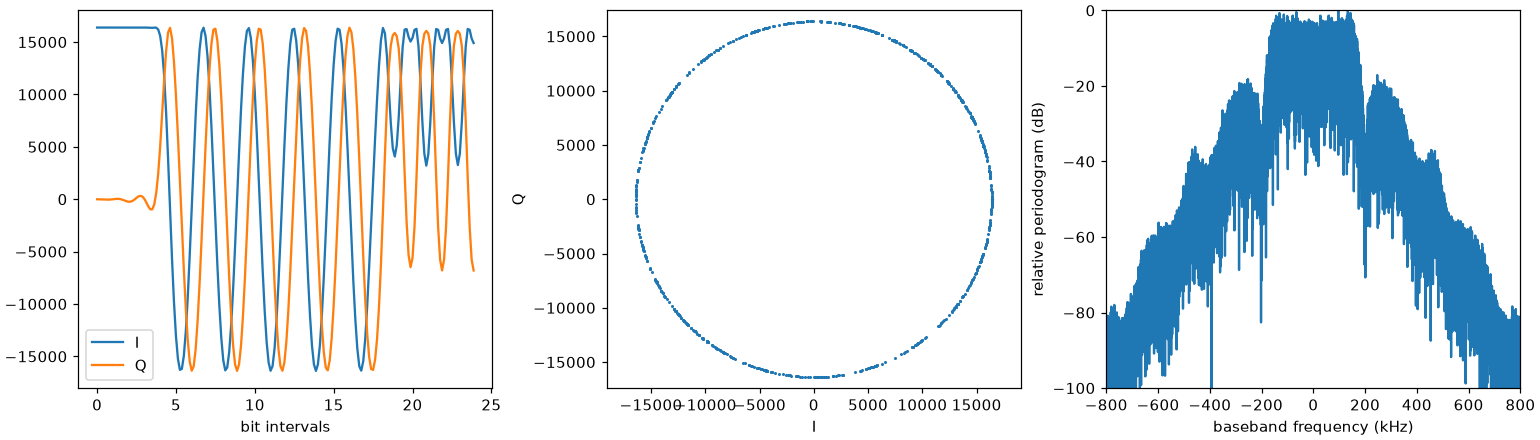

In [3]:
fig, ax = plt.subplots(1,3,figsize=(14,4),constrained_layout=True)
ax[0].plot(np.arange(192)/SPS,ideal.real[:192],label='I'); ax[0].plot(np.arange(192)/SPS,ideal.imag[:192],label='Q'); ax[0].legend(); ax[0].set_xlabel('bit intervals')
ax[1].plot(ideal.real[:1024],ideal.imag[:1024],'.',ms=2); ax[1].axis('equal'); ax[1].set_xlabel('I'); ax[1].set_ylabel('Q')
z=ideal[1024:1024+65536]; w=np.hanning(len(z)); p=abs(np.fft.fftshift(np.fft.fft(z*w)))**2
f=np.fft.fftshift(np.fft.fftfreq(len(z),1/FS))
ax[2].plot(f/1000,10*np.log10(np.maximum(p/p.max(),1e-12))); ax[2].set_xlim(-800,800); ax[2].set_ylim(-100,0); ax[2].set_xlabel('baseband frequency (kHz)'); ax[2].set_ylabel('relative periodogram (dB)')
fig.savefig('results/iq-spectrum.png',dpi=150)
plt.show()

## Continue with Notebook 2

[Fixed-point model and RTL/HDL mapping](pcm_fm_low_level.ipynb) contains integer widths, rounding, error plots, sample traces, enable behavior and the proposed hardware block interfaces.
